Homework 9 – Cartography with Matplotlib

By Antoaneta Chakarova for Geog592

10/20/2026

In [1]:
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

In [2]:
species = ["Arundinaria gigantea", "Arundinaria tecta"]
year = 2025

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # find the GBIF ID for the species name
    match = requests.get(
        f"{api}/species/match",
        params={"name": name}
    ).json()

    taxon_key = match["usageKey"]
    species_records = []

    # GBIF returns a maximum of 300 records in one request
    # keep requesting records until GBIF says there are no more
    while True:
        data = requests.get(
            f"{api}/occurrence/search",
            params={
                "taxon_key": taxon_key,
                "country": "US",
                "year": year,
                "has_coordinate": "true",
                "limit": 300,

                # start after the records we already downloaded
                "offset": len(species_records)
            }
        ).json()

        # keep only the species name and coordinates needed for mapping
        for record in data["results"]:
            records.append({
                "species": name,
                "longitude": record.get("decimalLongitude"),
                "latitude": record.get("decimalLatitude")
            })

        # keep track of how many records have already been downloaded
        species_records.extend(data["results"])

        # stop when GBIF reaches the last page of records
        if data["endOfRecords"]:
            break

    print(name, len(species_records))
# I only fixed this cell with Chatgpt because it was taking 10 minutes to get data with the original code.

Arundinaria gigantea 521
Arundinaria tecta 224


In [3]:
bamboo = pd.DataFrame(records)
bamboo = bamboo.dropna(subset=["longitude", "latitude"])
bamboo.head()
#They occupy overlapping but not identical parts of the southeastern US

,species,longitude,latitude
0,Arundinaria gigantea,-95.324580,30.054350
1,Arundinaria gigantea,-93.688767,34.033317
2,Arundinaria gigantea,-89.985747,34.792612
3,Arundinaria gigantea,-91.633497,35.679560
4,Arundinaria gigantea,-91.184272,31.449387


In [4]:
url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_state_500k.zip"
states = gpd.read_file(url)

states = states[~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])].copy()
states = states.to_crs(epsg=5070)

In [5]:
bamboo_points = gpd.GeoDataFrame(bamboo, geometry=gpd.points_from_xy(bamboo["longitude"], bamboo["latitude"]), crs="EPSG:4326")
bamboo_points = bamboo_points.to_crs(epsg=5070)

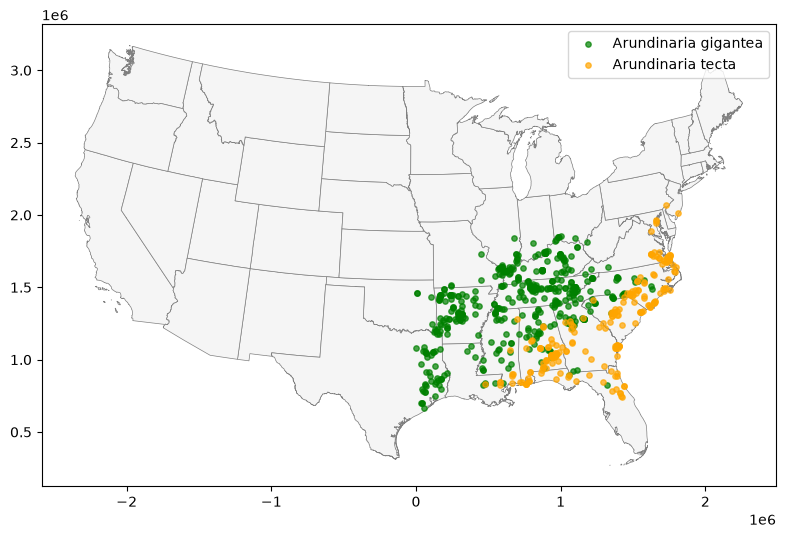

In [6]:
fig, ax = plt.subplots(figsize=(12, 6))

states.plot(ax=ax, facecolor="whitesmoke", edgecolor="gray", linewidth=0.5)
bamboo_points[bamboo_points["species"] == "Arundinaria gigantea"].plot(
    ax=ax,
    color="green",
    markersize=15,
    alpha=0.7,
    label="Arundinaria gigantea")

bamboo_points[bamboo_points["species"] == "Arundinaria tecta"].plot(
    ax=ax,
    color="orange",
    markersize=15,
    alpha=0.7,
    label="Arundinaria tecta")

ax.legend()
plt.show()

In [7]:
# attach each observation to the state where it occurs
points_by_state = gpd.sjoin(bamboo_points, states[["NAME", "geometry"]], how="inner", predicate="within")
points_by_state.head()

,species,longitude,latitude,geometry,index_right,NAME
0,Arundinaria gigantea,-95.324580,30.054350,POINT (65055.429 775637.577),35,Texas
1,Arundinaria gigantea,-93.688767,34.033317,POINT (211814.426 1221275.822),6,Arkansas
2,Arundinaria gigantea,-89.985747,34.792612,POINT (545497.165 1320866.422),39,Mississippi
3,Arundinaria gigantea,-91.633497,35.679560,POINT (391611.047 1411856.424),6,Arkansas
4,Arundinaria gigantea,-91.184272,31.449387,POINT (455794.975 942014.895),39,Mississippi


In [8]:
counts = (points_by_state.groupby(["NAME", "species"]).size().unstack(fill_value=0))
#make sure both species columns exist
if "Arundinaria gigantea" not in counts.columns:
    counts["Arundinaria gigantea"] = 0

if "Arundinaria tecta" not in counts.columns:
    counts["Arundinaria tecta"] = 0

counts.head()

species,Arundinaria gigantea,Arundinaria tecta
NAME,,
Alabama,32,59
Arkansas,75,0
Florida,2,20
Georgia,47,31
Illinois,38,0


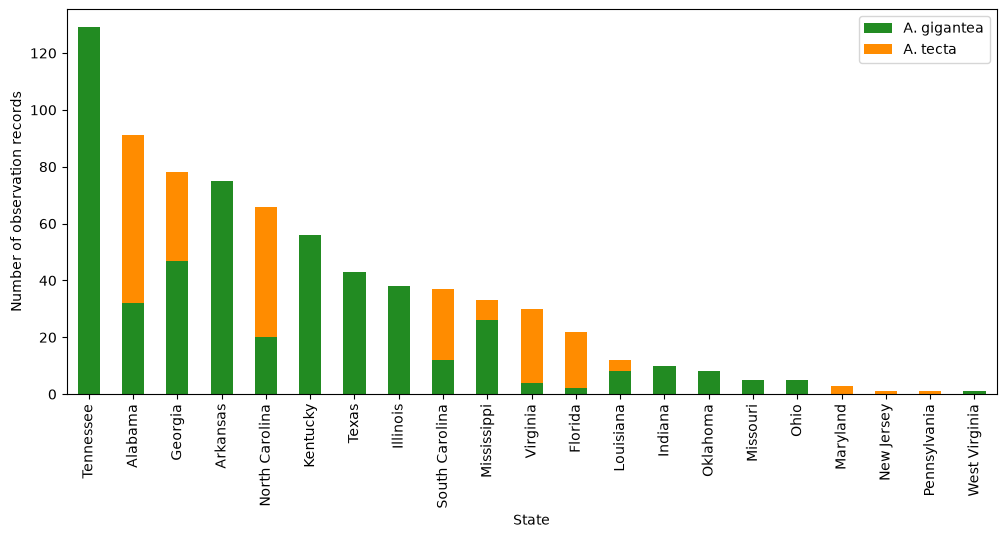

In [9]:
counts["total"] = (counts["Arundinaria gigantea"] + counts["Arundinaria tecta"])
counts = counts.sort_values("total", ascending=False)
counts[["Arundinaria gigantea", "Arundinaria tecta"]].plot(kind="bar", stacked=True, figsize=(12, 5), color=["forestgreen", "darkorange"])

plt.xlabel("State")
plt.ylabel("Number of observation records")
plt.legend(["A. gigantea", "A. tecta"])

In [10]:
# join the total observation count to the state polygons
state_map = states.merge(counts["total"], left_on="NAME", right_index=True, how="left")

# states with no observations get a value of 0
state_map["total"] = state_map["total"].fillna(0)
state_map.head()

,STATEFP,STATENS,GEOIDFQ,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry,total
0,35,00897535,0400000US35,35,NM,New Mexico,00,314198519809,726531289,"POLYGON ((-1231344.076 1018550.43, -1231015.83...",0.0
1,46,01785534,0400000US46,46,SD,South Dakota,00,196341670967,3387563375,"POLYGON ((-633765.574 2472338.835, -633207.122...",0.0
2,06,01779778,0400000US06,06,CA,California,00,403673433805,20291632828,"MULTIPOLYGON (((-2066923.367 1403703.122, -206...",0.0
3,21,01779786,0400000US21,21,KY,Kentucky,00,102266755818,2384136185,"MULTIPOLYGON (((584560.04 1518183.089, 585066....",56.0
4,01,01779775,0400000US01,01,AL,Alabama,00,131185561946,4581813708,"MULTIPOLYGON (((760323.731 857474.728, 760524....",91.0


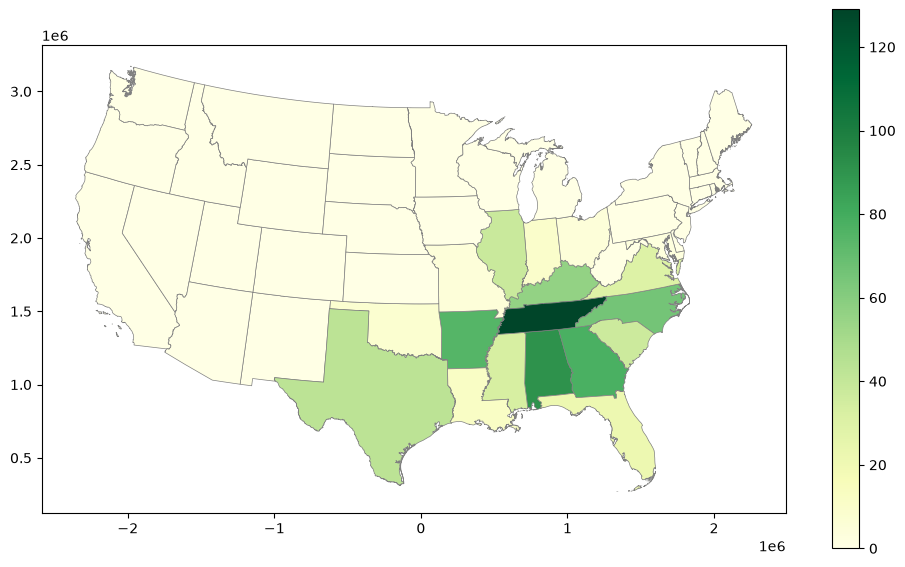

In [11]:
fig, ax = plt.subplots(figsize=(12, 7))

state_map.plot(column="total", cmap="YlGn", edgecolor="gray", linewidth=0.5, legend=True, ax=ax)
plt.show()

c:\Users\Tony\AppData\Local\Programs\Python\Python313\Lib\site-packages\mapclassify\classifiers.py:1767: UserWarning: Not enough unique values in array to form 5 classes. Setting k to 4.
  self.bins = quantile(y, k=k)
c:\Users\Tony\AppData\Local\Programs\Python\Python313\Lib\site-packages\geopandas\plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


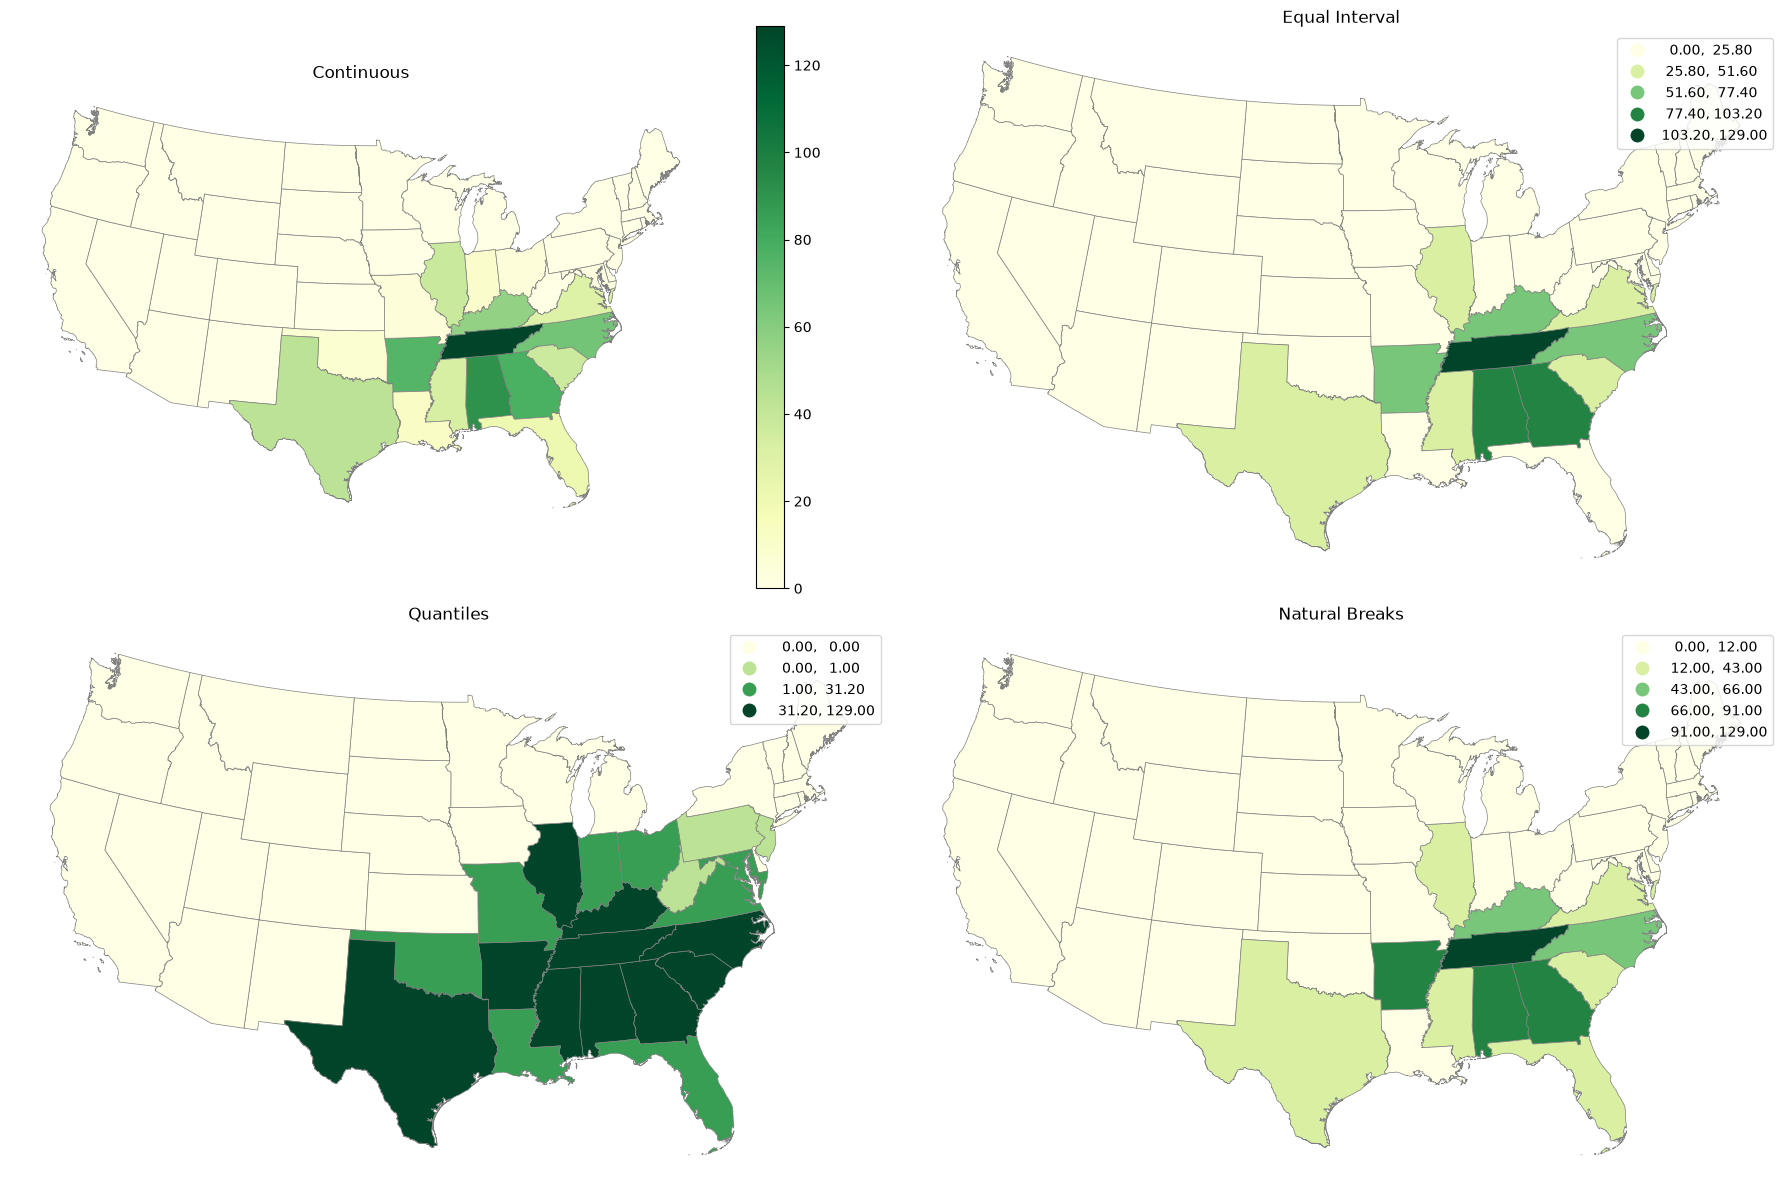

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

state_map.plot(
    column="total",
    cmap="YlGn",
    edgecolor="gray",
    linewidth=0.5,
    legend=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Continuous")

state_map.plot(
    column="total",
    scheme="equalinterval",
    k=5,
    cmap="YlGn",
    edgecolor="gray",
    linewidth=0.5,
    legend=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Equal Interval")

state_map.plot(
    column="total",
    scheme="quantiles",
    k=5,
    cmap="YlGn",
    edgecolor="gray",
    linewidth=0.5,
    legend=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Quantiles")

state_map.plot(
    column="total",
    scheme="fisherjenks",
    k=5,
    cmap="YlGn",
    edgecolor="gray",
    linewidth=0.5,
    legend=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Natural Breaks")

for ax in axes.flat:
    ax.set_axis_off()

plt.tight_layout()
#fig.savefig("bamboo_classification_2025.png", dpi=300,bbox_inches="tight")
plt.show()

In [13]:
# join the separate species counts to the state polygons
bivariate = states.merge(counts[["Arundinaria gigantea", "Arundinaria tecta"]], left_on="NAME", right_index=True, how="left")
bivariate["Arundinaria gigantea"] = bivariate["Arundinaria gigantea"].fillna(0)
bivariate["Arundinaria tecta"] = bivariate["Arundinaria tecta"].fillna(0)

bivariate.head()

,STATEFP,STATENS,GEOIDFQ,GEOID,STUSPS,NAME,LSAD,ALAND,AWATER,geometry,Arundinaria gigantea,Arundinaria tecta
0,35,00897535,0400000US35,35,NM,New Mexico,00,314198519809,726531289,"POLYGON ((-1231344.076 1018550.43, -1231015.83...",0.0,0.0
1,46,01785534,0400000US46,46,SD,South Dakota,00,196341670967,3387563375,"POLYGON ((-633765.574 2472338.835, -633207.122...",0.0,0.0
2,06,01779778,0400000US06,06,CA,California,00,403673433805,20291632828,"MULTIPOLYGON (((-2066923.367 1403703.122, -206...",0.0,0.0
3,21,01779786,0400000US21,21,KY,Kentucky,00,102266755818,2384136185,"MULTIPOLYGON (((584560.04 1518183.089, 585066....",56.0,0.0
4,01,01779775,0400000US01,01,AL,Alabama,00,131185561946,4581813708,"MULTIPOLYGON (((760323.731 857474.728, 760524....",32.0,59.0


In [14]:
# use the median of states with observations to split each species into lower and higher counts
gigantea_median = bivariate.loc[bivariate["Arundinaria gigantea"] > 0, "Arundinaria gigantea"].median()
tecta_median = bivariate.loc[bivariate["Arundinaria tecta"] > 0, "Arundinaria tecta"].median()

print("A. gigantea median:", gigantea_median)
print("A. tecta median:", tecta_median)

A. gigantea median: 16.0
A. tecta median: 20.0


In [ ]:
# 0 = no observations, 1 = lower counts, 2 = higher counts
bivariate["gigantea_class"] = 0

bivariate.loc[(bivariate["Arundinaria gigantea"] > 0) & (bivariate["Arundinaria gigantea"] <= gigantea_median),
    "gigantea_class"] = 1
bivariate.loc[bivariate["Arundinaria gigantea"] > gigantea_median,
    "gigantea_class"] = 2

In [16]:
bivariate["tecta_class"] = 0

bivariate.loc[(bivariate["Arundinaria tecta"] > 0) & (bivariate["Arundinaria tecta"] <= tecta_median),
    "tecta_class"] = 1
bivariate.loc[bivariate["Arundinaria tecta"] > tecta_median,
    "tecta_class"] = 2

In [17]:
# rows represent A. tecta and columns represent A. gigantea
palette = np.array([
    ["#eeeeee", "#b8d8ba", "#4c956c"],
    ["#f3c7a7", "#c7aa78", "#78866b"],
    ["#df7f4f", "#ad754e", "#6b5d3f"]
])

colors = []

# assign one color using the class of both species
for i in range(len(bivariate)):
    tecta = int(bivariate.iloc[i]["tecta_class"])
    gigantea = int(bivariate.iloc[i]["gigantea_class"])

    colors.append(palette[tecta, gigantea])

bivariate["color"] = colors


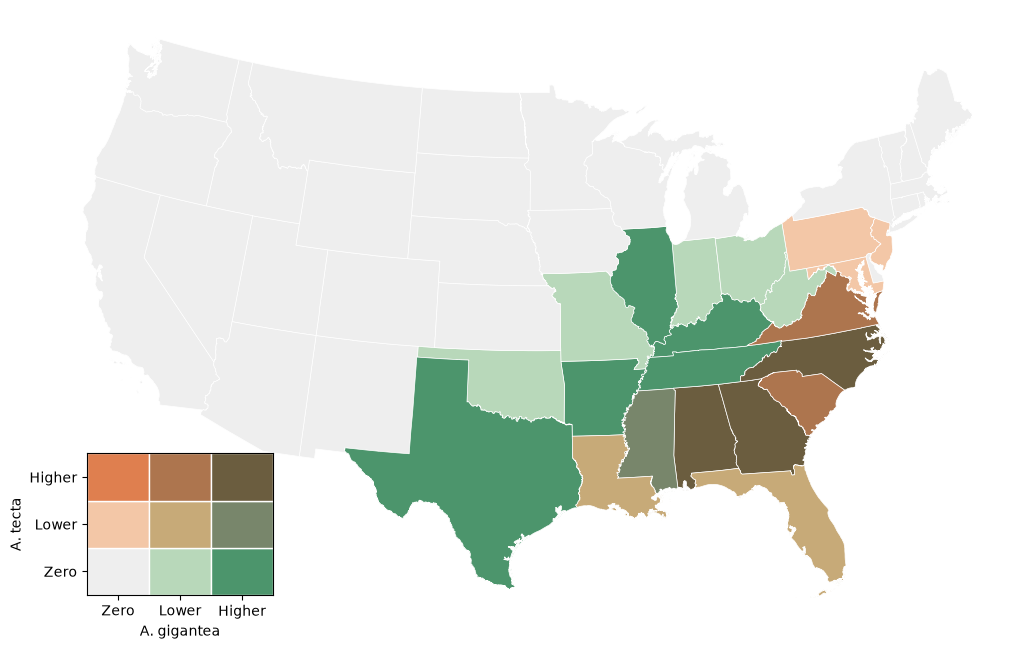

In [18]:
fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(color=bivariate["color"], edgecolor="white", linewidth=0.5, ax=ax)
ax.set_axis_off()

# add the 3 x 3 bivariate legend inside the map
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for tecta in range(3):
    for gigantea in range(3):
        legend_ax.add_patch(
            Rectangle(
                (gigantea, tecta),
                1,
                1,
                facecolor=palette[tecta, gigantea],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])

legend_ax.set_xticklabels(["Zero", "Lower", "Higher"])
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"])

legend_ax.set_xlabel("A. gigantea")
legend_ax.set_ylabel("A. tecta")

#fig.savefig("bamboo_bivariate_2025.png", dpi=300, bbox_inches="tight")
plt.show()

The different classification schemes show that the same species data can look different depending on how observation counts are grouped.
- Equal interval is easy to interpret because each class covers the same numerical range, but states with high counts can make lower-count states look very similar. 
- Quantiles make spatial differences easier to see because the states are divided more evenly among classes, although states with different counts can end up in the same group. 
- Natural breaks uses gaps in the data, which can show clusters more clearly, but the class boundaries depend on the specific dataset.

The bivariate map makes it easier to see where both species were recorded in 2025 and where one had more observations than the other. A limitation is that GBIF data represents observations and not true population size, so higher counts can also reflect greater observation effort.

In [19]:
import mapclassify


In [20]:
positive = state_map.loc[state_map["total"] > 0].copy() #keep only states with at least one observation
centers = positive.geometry.centroid #use state centroids for the symbol locations
classification = mapclassify.FisherJenks(positive["total"], k=3) #classify the totals into 3 groups so the symbol sizes are easier to read
sizes = np.array([60, 250, 700]) #circle sizes for the 3 classes

C:\Users\Tony\AppData\Roaming\Python\Python313\site-packages\IPython\core\interactiveshell.py:3775: UserWarning: Numba not installed. Using slow pure python version.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [21]:
def propSymbol_class(ax):
    
    positive = state_map.loc[state_map["total"] > 0].copy()
    centers = positive.geometry.centroid

    classification = mapclassify.FisherJenks(positive["total"], k=3)

    # circle sizes for low, medium, and high classes
    sizes = np.array([60, 250, 700])

    state_map.plot(ax=ax, facecolor="whitesmoke", edgecolor="gray", linewidth=0.5)

    ax.scatter(centers.x, centers.y, s=sizes[classification.yb], color="forestgreen", alpha=0.6, edgecolors="white", linewidths=0.5)

    # legend uses the actual observation range in each class
    for class_id, size in enumerate(sizes):
        values = positive.loc[classification.yb == class_id, "total"]
        ax.scatter([], [], s=size, color="forestgreen", alpha=0.6, edgecolors="white", label=f"{values.min():,.0f}–{values.max():,.0f}")

    ax.legend(title="Observation records", loc="lower left", labelspacing=1.5)
    ax.set_axis_off()

    return ax

C:\Users\Tony\AppData\Local\Temp\ipykernel_11308\812001404.py:3: UserWarning: Numba not installed. Using slow pure python version.
  propSymbol_class(ax)


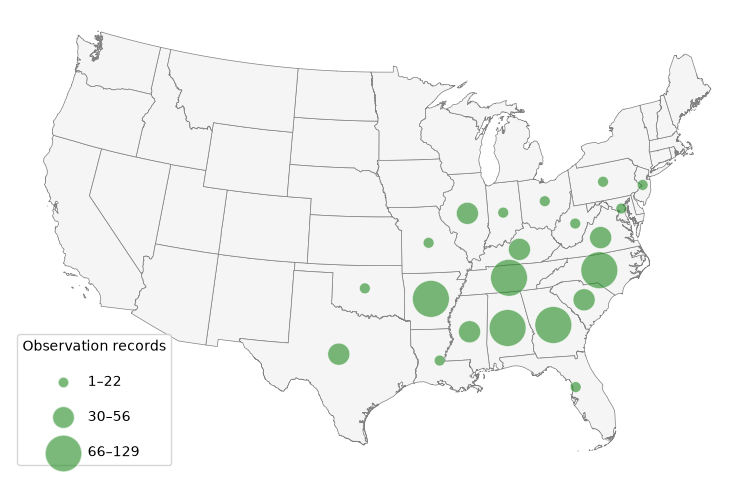

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))

propSymbol_class(ax)
#fig.savefig("bamboo_proportional_symbol_2025.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
from shapely.geometry import Polygon #Hexagon map

In [24]:
points = points_by_state.copy()
radius = 100000 #hexagon size in meters
xmin, ymin, xmax, ymax = states.total_bounds
hexagons = []

for column, x in enumerate(np.arange(xmin - radius, xmax + 2 * radius, 1.5 * radius)):
    for y in np.arange(ymin - radius, ymax + 2 * radius, np.sqrt(3) * radius):
        center_y = y + (column % 2) * np.sqrt(3) * radius / 2 #Move every other column up by half a hexagon
        angles = np.arange(6) * np.pi / 3
        hexagons.append(Polygon([(x + radius * np.cos(angle), center_y + radius * np.sin(angle)) for angle in angles]))

In [25]:
grid = gpd.GeoDataFrame({"hex_id": range(len(hexagons))}, geometry=hexagons, crs=states.crs)

#Only keep hexagons that overlap the US
region = states.geometry.union_all()
grid = grid.loc[grid.intersects(region)].copy()

In [26]:
points = points.drop(columns=["index_right"]) #remove the index column created by the previous spatial join
points = points.reset_index(drop=True)
points["point_id"] = points.index

joined = gpd.sjoin(points, grid[["hex_id", "geometry"]], how="inner", predicate="intersects") #Assign every bamboo observation to a hexagon
joined = joined.sort_values("hex_id").drop_duplicates("point_id") #Make sure a point on a hexagon edge is only counted once

In [27]:
hex_counts = joined.groupby(["hex_id", "species"]).size().unstack(fill_value=0)
if "Arundinaria gigantea" not in hex_counts.columns:
    hex_counts["Arundinaria gigantea"] = 0
if "Arundinaria tecta" not in hex_counts.columns:
    hex_counts["Arundinaria tecta"] = 0

In [28]:
grid = grid.merge(hex_counts, left_on="hex_id", right_index=True, how="left")
species = ["Arundinaria gigantea", "Arundinaria tecta"]

grid[species] = grid[species].fillna(0)
grid["total"] = grid[species].sum(axis=1)

In [29]:
def hexCountMap(ax, grid, states):
    grid.plot(ax=ax, column="total", cmap="YlGn", edgecolor="white", linewidth=0.2, legend=True, legend_kwds={"label": "Number of observation records"})
    states.boundary.plot(ax=ax, color="gray", linewidth=0.4)
    ax.set_axis_off()
    return ax

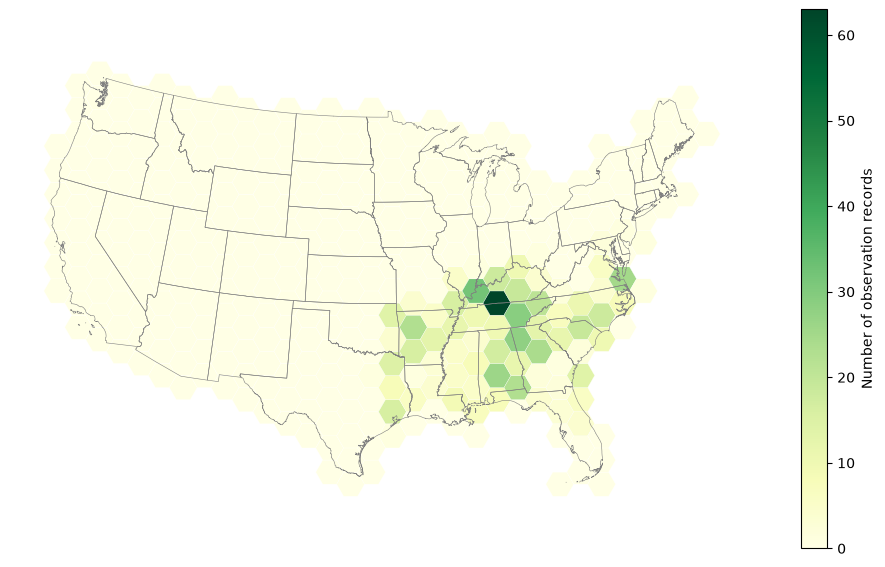

In [30]:
fig, ax = plt.subplots(figsize=(12, 7))
hexCountMap(ax, grid, states)

#fig.savefig("bamboo_hexagon_2025.png", dpi=300, bbox_inches="tight")
plt.show()